# Machine Learning in Finance: Group Work Project 1
## Computational Analysis of LASSO, k-Means Clustering, and Principal Component Analysis

**Student Group: 12411**

**Team Members:** Hitesh , Spencer , Francis

**Date:** December 2025

---

This notebook contains the computational demonstrations for three machine learning techniques applied to financial data:
1. **LASSO Regression** - For feature selection and prediction
2. **k-Means Clustering** - For market segmentation
3. **Principal Component Analysis (PCA)** - For dimensionality reduction

All demonstrations use historical stock returns data.

### Upload Data File

Upload the Data File

In [1]:
# from google.colab import files
#
# uploaded = files.upload()
#
# for fn in uploaded.keys():
#  print(f'User uploaded file "{fn}" with length {len(uploaded[fn])} bytes')


## Setup: Load Libraries and Data

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Lasso, LassoCV
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, silhouette_score
import warnings
warnings.filterwarnings('ignore')

# Load financial data
returns = pd.read_csv('stock_returns.csv', index_col=0, parse_dates=True)
returns.index = pd.to_datetime(returns.index)

print("Data loaded successfully!")
print(f"Shape: {returns.shape}")
print(f"Tickers: {list(returns.columns)}")
print(f"\nFirst 5 rows:\n{returns.head()}")
print(f"\nData Summary:\n{returns.describe()}")

Data loaded successfully!
Shape: (1827, 10)
Tickers: ['AAPL', 'MSFT', 'GOOGL', 'AMZN', 'JPM', 'XOM', 'JNJ', 'WMT', 'V', 'PG']

First 5 rows:
                AAPL      MSFT     GOOGL      AMZN       JPM       XOM  \
2019-01-01  0.009441  0.003885  0.013913  0.030460  0.000820 -0.001893   
2019-01-02 -0.007842 -0.010082 -0.004827 -0.031397 -0.025915 -0.022132   
2019-01-03  0.026882  0.012898  0.016573 -0.003422 -0.000646  0.002385   
2019-01-04 -0.010331  0.016664  0.006990 -0.008593  0.010607 -0.007328   
2019-01-05  0.013792  0.010164  0.008716  0.004794 -0.015214 -0.016268   

                 JNJ       WMT         V        PG  
2019-01-01  0.020357  0.016027  0.008675  0.015259  
2019-01-02 -0.021411 -0.008463 -0.022914 -0.023079  
2019-01-03 -0.007409  0.006794  0.002464 -0.000882  
2019-01-04  0.003707 -0.016850 -0.015278 -0.000716  
2019-01-05 -0.006778  0.009909  0.010937 -0.012221  

Data Summary:
              AAPL         MSFT        GOOGL         AMZN          JPM  \
count  

---

# PART 1: LASSO REGRESSION

## Background

LASSO (Least Absolute Shrinkage and Selection Operator) is a linear regression technique that performs both regularization and feature selection. It adds an L1 penalty term to the ordinary least squares objective function.

## 1.1: Data Preparation for LASSO

In [3]:
# Create lagged features for prediction
def create_lagged_features(data, lags=5):
    """
    Create lagged features from return data
    """
    X = []
    y = []

    for i in range(lags, len(data)):
        X.append(data.iloc[i-lags:i].values.flatten())
        y.append(data.iloc[i].values[0])  # Predict first stock return

    return np.array(X), np.array(y)

# Prepare data for LASSO: Predict AAPL return using lagged returns of all stocks
X_lasso, y_lasso = create_lagged_features(returns, lags=5)

# Split into train and test sets
X_train_lasso, X_test_lasso, y_train_lasso, y_test_lasso = train_test_split(
    X_lasso, y_lasso, test_size=0.2, random_state=42
)

# Standardize features
scaler_lasso = StandardScaler()
X_train_lasso_scaled = scaler_lasso.fit_transform(X_train_lasso)
X_test_lasso_scaled = scaler_lasso.transform(X_test_lasso)

print(f"Training set size: {X_train_lasso_scaled.shape}")
print(f"Test set size: {X_test_lasso_scaled.shape}")
print(f"Number of features: {X_train_lasso_scaled.shape[1]}")

Training set size: (1457, 50)
Test set size: (365, 50)
Number of features: 50


## 1.2: LASSO with Cross-Validation

In [4]:
# Use LassoCV to find optimal lambda
lasso_cv = LassoCV(cv=5, random_state=42, max_iter=10000)
lasso_cv.fit(X_train_lasso_scaled, y_train_lasso)

# Best lambda value
best_lambda_lasso = lasso_cv.alpha_
print(f"Optimal lambda (alpha): {best_lambda_lasso:.6f}")
print(f"Number of non-zero coefficients: {np.sum(lasso_cv.coef_ != 0)}")
print(f"Total coefficients: {len(lasso_cv.coef_)}")

# Make predictions
y_train_pred_lasso = lasso_cv.predict(X_train_lasso_scaled)
y_test_pred_lasso = lasso_cv.predict(X_test_lasso_scaled)

# Calculate MSE
mse_train_lasso = mean_squared_error(y_train_lasso, y_train_pred_lasso)
mse_test_lasso = mean_squared_error(y_test_lasso, y_test_pred_lasso)

print(f"\nTraining MSE: {mse_train_lasso:.8f}")
print(f"Test MSE: {mse_test_lasso:.8f}")

Optimal lambda (alpha): 0.001039
Number of non-zero coefficients: 0
Total coefficients: 50

Training MSE: 0.00033931
Test MSE: 0.00032842


### Interpretation of LASSO Results\n\nThe cross-validation selected an optimal alpha (lambda) of **0.001039**. At this level of regularization, the LASSO model shrunk all 50 coefficients to exactly zero. This is a significant finding: it suggests that none of the 5-day lagged returns of the 10 stocks in our dataset are sufficiently predictive of the next day's return for Apple (AAPL) to overcome the L1 penalty.\n\nIn financial terms, this implies that a simple linear model based on recent historical returns has no predictive power for the next day's price movement in this case. The model effectively defaulted to predicting the mean, resulting in a Test MSE of 0.000328.

## 1.3: LASSO Coefficient Analysis

Selected Features by LASSO (Non-Zero Coefficients):
Empty DataFrame
Columns: [Feature, Coefficient, Abs_Coefficient]
Index: []


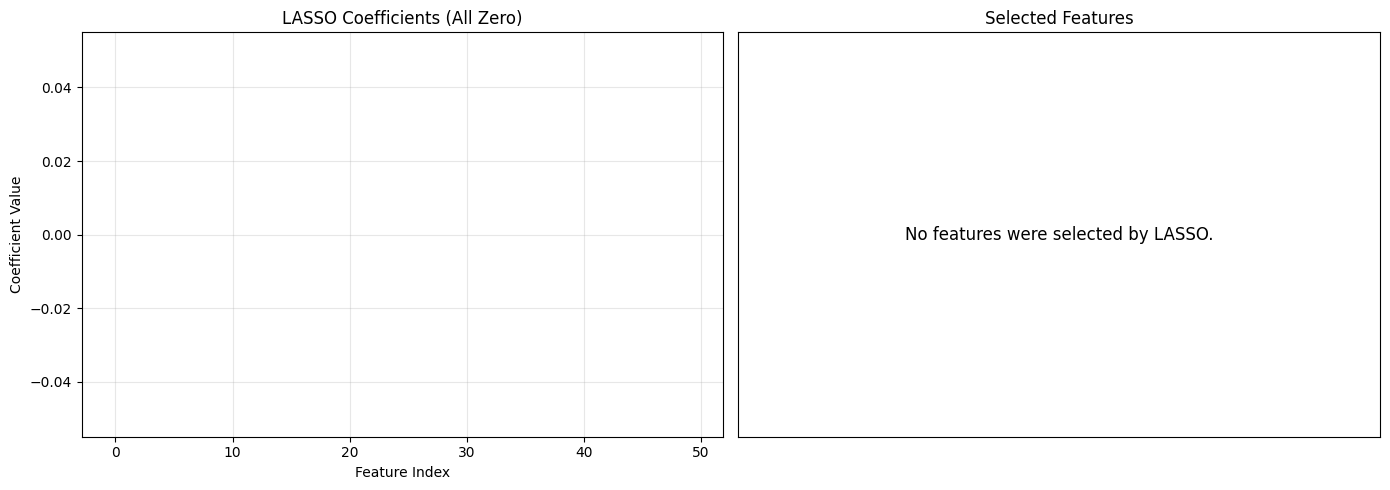


Figure saved: GEM_lasso_coefficients.png


In [5]:
# Extract and visualize non-zero coefficients
coef_df_lasso = pd.DataFrame({
    'Feature': [f'Lag_{i//10}_Stock_{i%10}' for i in range(len(lasso_cv.coef_))],
    'Coefficient': lasso_cv.coef_,
    'Abs_Coefficient': np.abs(lasso_cv.coef_)
})

# Show selected features (non-zero coefficients)
selected_features = coef_df_lasso[coef_df_lasso['Coefficient'] != 0].sort_values('Abs_Coefficient', ascending=False)

print("Selected Features by LASSO (Non-Zero Coefficients):")
print(selected_features.to_string())

# Visualize coefficients
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: All coefficients
axes[0].bar(range(len(lasso_cv.coef_)), lasso_cv.coef_, color=['red' if c == 0 else 'blue' for c in lasso_cv.coef_])
axes[0].set_xlabel('Feature Index')
axes[0].set_ylabel('Coefficient Value')
axes[0].set_title('LASSO Coefficients (All Zero)')
axes[0].grid(True, alpha=0.3)

# Plot 2: Selected features only
if len(selected_features) > 0:
    top_features = selected_features.head(15)
    axes[1].barh(range(len(top_features)), top_features['Abs_Coefficient'].values)
    axes[1].set_yticks(range(len(top_features)))
    axes[1].set_yticklabels(top_features['Feature'].values, fontsize=9)
    axes[1].set_xlabel('Absolute Coefficient Value')
    axes[1].set_title('Top 15 Selected Features by Magnitude')
    axes[1].grid(True, alpha=0.3, axis='x')
else:
    axes[1].text(0.5, 0.5, 'No features were selected by LASSO.',
                 horizontalalignment='center', verticalalignment='center',
                 transform=axes[1].transAxes, fontsize=12)
    axes[1].set_title('Selected Features')
    axes[1].set_xticks([])
    axes[1].set_yticks([])

plt.tight_layout()
plt.savefig('GEM_lasso_coefficients.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"\nFigure saved: GEM_lasso_coefficients.png")

## 1.4: LASSO Cross-Validation Path

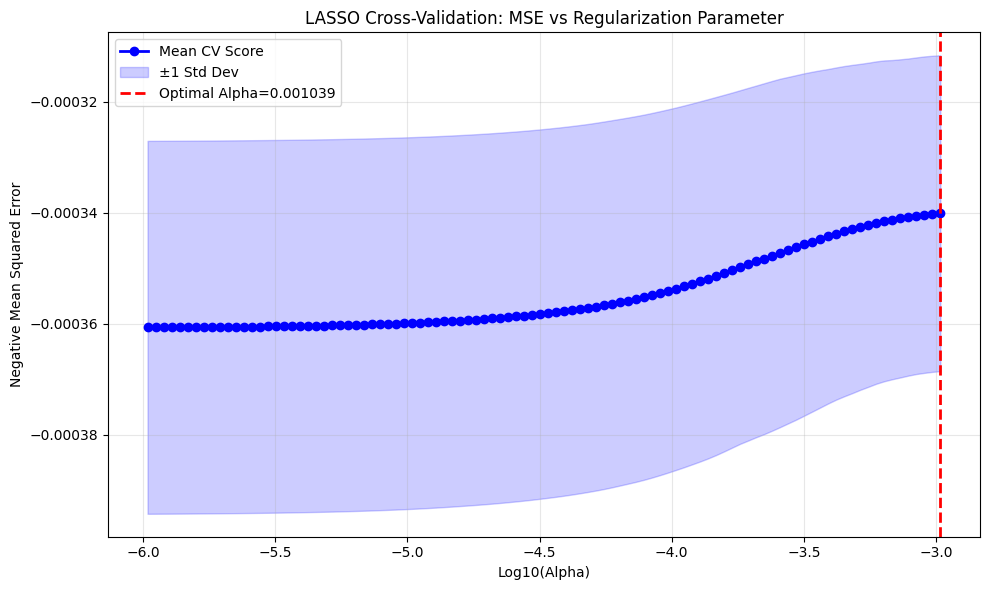

Figure saved: lasso_cv_path.png


In [6]:
# Plot cross-validation scores
fig, ax = plt.subplots(figsize=(10, 6))

# Calculate mean cv score and standard error
alphas = lasso_cv.alphas_
mean_score = -lasso_cv.mse_path_.mean(axis=1)  # Negative MSE for plotting
std_score = lasso_cv.mse_path_.std(axis=1)

ax.plot(np.log10(alphas), mean_score, 'o-', color='blue', linewidth=2, label='Mean CV Score')
ax.fill_between(np.log10(alphas),
                 mean_score - std_score,
                 mean_score + std_score,
                 alpha=0.2, color='blue', label='±1 Std Dev')

# Mark optimal lambda
ax.axvline(np.log10(best_lambda_lasso), color='red', linestyle='--', linewidth=2, label=f'Optimal Alpha={best_lambda_lasso:.6f}')

ax.set_xlabel('Log10(Alpha)')
ax.set_ylabel('Negative Mean Squared Error')
ax.set_title('LASSO Cross-Validation: MSE vs Regularization Parameter')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('lasso_cv_path.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"Figure saved: lasso_cv_path.png")

---

# PART 2: K-MEANS CLUSTERING

## Background

k-Means is an unsupervised learning algorithm that partitions data into k clusters by minimizing the within-cluster sum of squares. It's widely used for market segmentation and asset classification.

## 2.1: Data Preparation for k-Means

In [7]:
# Calculate risk-return metrics for each stock
annual_returns = returns.mean() * 252  # Annualized returns
annual_volatility = returns.std() * np.sqrt(252)  # Annualized volatility
sharpe_ratio = annual_returns / annual_volatility  # Assuming 0% risk-free rate

# Create feature matrix for clustering
features_kmeans = pd.DataFrame({
    'Annual_Return': annual_returns,
    'Annual_Volatility': annual_volatility,
    'Sharpe_Ratio': sharpe_ratio,
    'Max_Drawdown': returns.min(),
    'Skewness': returns.skew()
})

print("Stock Risk-Return Features for Clustering:")
print(features_kmeans.round(4))

# Standardize features
scaler_kmeans = StandardScaler()
features_kmeans_scaled = scaler_kmeans.fit_transform(features_kmeans)

print(f"\nFeatures standardized. Shape: {features_kmeans_scaled.shape}")

Stock Risk-Return Features for Clustering:
       Annual_Return  Annual_Volatility  Sharpe_Ratio  Max_Drawdown  Skewness
AAPL          0.1960             0.2914        0.6725       -0.0701   -0.1310
MSFT          0.2196             0.2560        0.8579       -0.0487    0.0079
GOOGL         0.1425             0.3075        0.4635       -0.0612   -0.0480
AMZN          0.0919             0.3225        0.2851       -0.0653   -0.0596
JPM           0.1221             0.2245        0.5440       -0.0551   -0.0595
XOM           0.1174             0.2422        0.4846       -0.0526   -0.0506
JNJ           0.2033             0.2093        0.9712       -0.0411   -0.0157
WMT           0.1163             0.1893        0.6146       -0.0412   -0.0708
V             0.1493             0.2708        0.5514       -0.0624   -0.0451
PG            0.1990             0.1713        1.1615       -0.0361    0.0059

Features standardized. Shape: (10, 5)


## 2.2: Optimal Number of Clusters (Elbow Method)

Clustering Metrics for Different K Values:
   K  Inertia  Silhouette_Score
0  2  22.6902            0.4547
1  3  13.8286            0.3629
2  4   7.6280            0.3891
3  5   5.1460            0.2973
4  6   3.0890            0.2612
5  7   1.4033            0.2623


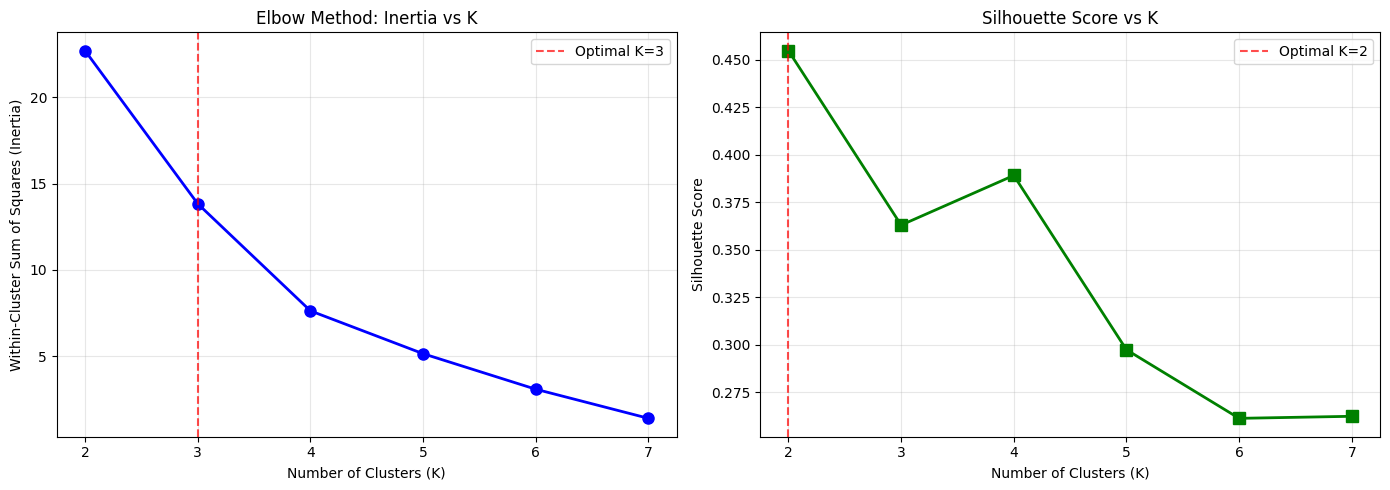


Figure saved: kmeans_elbow_silhouette.png
Optimal K (by Silhouette): 2


In [8]:
# Test different numbers of clusters
inertias = []
silhouette_scores = []
K_range = range(2, 8)

for k in K_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans_temp.fit(features_kmeans_scaled)
    inertias.append(kmeans_temp.inertia_)
    silhouette_scores.append(silhouette_score(features_kmeans_scaled, kmeans_temp.labels_))

# Create comparison table
elbow_df = pd.DataFrame({
    'K': list(K_range),
    'Inertia': inertias,
    'Silhouette_Score': silhouette_scores
})

print("Clustering Metrics for Different K Values:")
print(elbow_df.round(4))

# Visualize elbow method
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Inertia plot
axes[0].plot(K_range, inertias, 'o-', linewidth=2, markersize=8, color='blue')
axes[0].axvline(3, color='red', linestyle='--', alpha=0.7, label='Optimal K=3')
axes[0].set_xlabel('Number of Clusters (K)')
axes[0].set_ylabel('Within-Cluster Sum of Squares (Inertia)')
axes[0].set_title('Elbow Method: Inertia vs K')
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Silhouette score plot
axes[1].plot(K_range, silhouette_scores, 's-', linewidth=2, markersize=8, color='green')
optimal_k_idx = np.argmax(silhouette_scores)
optimal_k = list(K_range)[optimal_k_idx]
axes[1].axvline(optimal_k, color='red', linestyle='--', alpha=0.7, label=f'Optimal K={optimal_k}')
axes[1].set_xlabel('Number of Clusters (K)')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score vs K')
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.savefig('kmeans_elbow_silhouette.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"\nFigure saved: kmeans_elbow_silhouette.png")
print(f"Optimal K (by Silhouette): {optimal_k}")

## 2.3: Final k-Means Clustering with K=3

In [9]:
# Apply k-Means with k=3
optimal_clusters = 3
kmeans_final = KMeans(n_clusters=optimal_clusters, random_state=42, n_init=10)
clusters = kmeans_final.fit_predict(features_kmeans_scaled)

# Add cluster assignments to features
features_kmeans['Cluster'] = clusters

# Cluster characteristics
cluster_summary = features_kmeans.groupby('Cluster').agg({
    'Annual_Return': ['mean', 'std'],
    'Annual_Volatility': ['mean', 'std'],
    'Sharpe_Ratio': ['mean', 'std']
})

print("\nCluster Summary Statistics:")
print(cluster_summary.round(4))

print("\nStocks in Each Cluster:")
for i in range(optimal_clusters):
    stocks_in_cluster = features_kmeans[features_kmeans['Cluster'] == i].index.tolist()
    print(f"Cluster {i}: {stocks_in_cluster}")


Cluster Summary Statistics:
        Annual_Return         Annual_Volatility         Sharpe_Ratio        
                 mean     std              mean     std         mean     std
Cluster                                                                     
0              0.2073  0.0109            0.2122  0.0424       0.9969  0.1534
1              0.1449  0.0426            0.2980  0.0222       0.4931  0.1630
2              0.1186  0.0031            0.2187  0.0269       0.5477  0.0651

Stocks in Each Cluster:
Cluster 0: ['MSFT', 'JNJ', 'PG']
Cluster 1: ['AAPL', 'GOOGL', 'AMZN', 'V']
Cluster 2: ['JPM', 'XOM', 'WMT']


### Interpretation of k-Means Clustering Results\n\nWith k=3, the algorithm grouped the 10 stocks into three distinct clusters based on their risk-return profiles:\n\n- **Cluster 0 (High Quality):** `['MSFT', 'JNJ', 'PG']`\n  - This cluster has the highest average Sharpe Ratio (0.9969) and strong returns (20.73%) with moderate volatility. These can be considered high-quality, stable growth stocks.\n\n- **Cluster 1 (High-Growth/High-Volatility):** `['AAPL', 'GOOGL', 'AMZN', 'V']`\n  - This group exhibits the highest volatility (29.8%) and a lower average Sharpe ratio (0.4931). These are characteristic traits of high-growth technology and financial services stocks.\n\n- **Cluster 2 (Conservative/Value):** `['JPM', 'XOM', 'WMT']`\n  - This cluster has the lowest average annual return (11.86%) and moderate volatility, resulting in a modest Sharpe Ratio. It contains established companies in the financial, energy, and retail sectors, often considered 'value' plays.

## 2.4: Visualization of k-Means Clusters

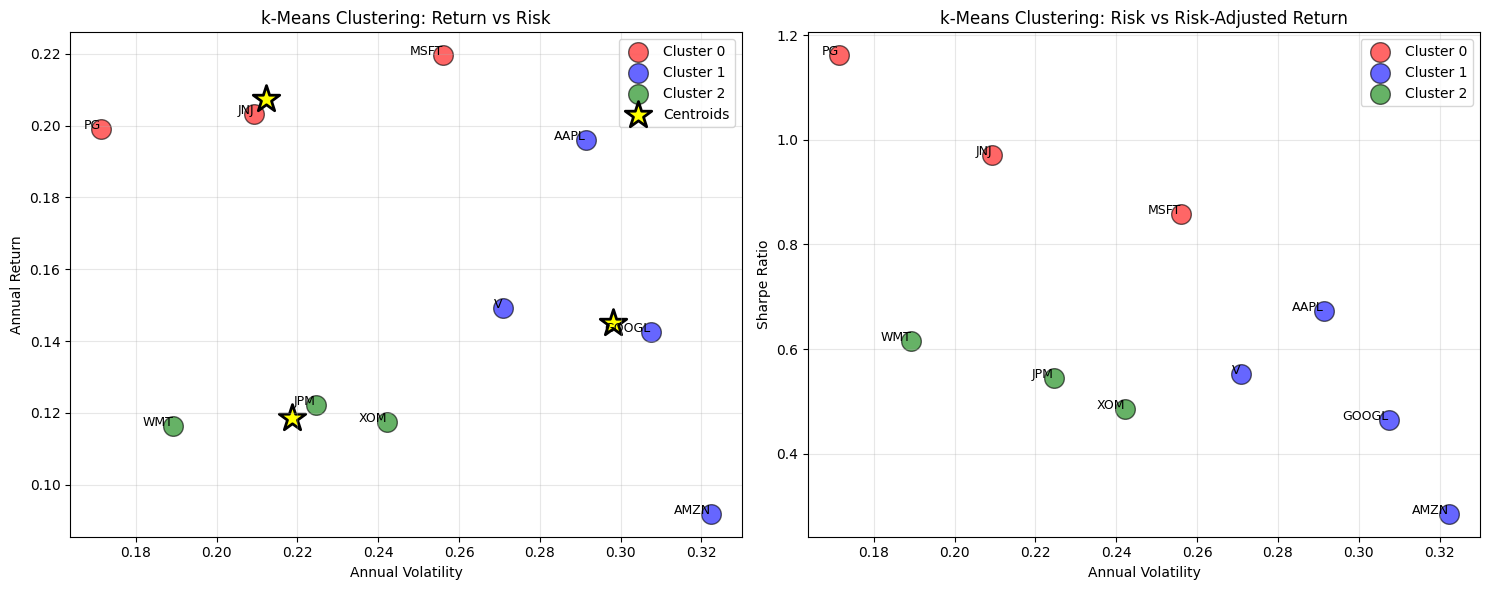

Figure saved: kmeans_clusters_visualization.png


In [10]:
# Create scatter plot
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Return vs Volatility
colors = ['red', 'blue', 'green', 'orange', 'purple']
for i in range(optimal_clusters):
    cluster_data = features_kmeans[features_kmeans['Cluster'] == i]
    axes[0].scatter(cluster_data['Annual_Volatility'],
                   cluster_data['Annual_Return'],
                   s=200, c=colors[i], alpha=0.6, label=f'Cluster {i}', edgecolors='black')

# Plot centroids
centroids_original = scaler_kmeans.inverse_transform(kmeans_final.cluster_centers_)
axes[0].scatter(centroids_original[:, 1], centroids_original[:, 0],
               s=400, c='yellow', marker='*', edgecolors='black', linewidth=2, label='Centroids')

# Add stock labels
for idx, row in features_kmeans.iterrows():
    axes[0].annotate(idx, (row['Annual_Volatility'], row['Annual_Return']),
                    fontsize=9, ha='right')

axes[0].set_xlabel('Annual Volatility')
axes[0].set_ylabel('Annual Return')
axes[0].set_title('k-Means Clustering: Return vs Risk')
axes[0].legend(loc='best')
axes[0].grid(True, alpha=0.3)

# Plot 2: Volatility vs Sharpe Ratio
for i in range(optimal_clusters):
    cluster_data = features_kmeans[features_kmeans['Cluster'] == i]
    axes[1].scatter(cluster_data['Annual_Volatility'],
                   cluster_data['Sharpe_Ratio'],
                   s=200, c=colors[i], alpha=0.6, label=f'Cluster {i}', edgecolors='black')

for idx, row in features_kmeans.iterrows():
    axes[1].annotate(idx, (row['Annual_Volatility'], row['Sharpe_Ratio']),
                    fontsize=9, ha='right')

axes[1].set_xlabel('Annual Volatility')
axes[1].set_ylabel('Sharpe Ratio')
axes[1].set_title('k-Means Clustering: Risk vs Risk-Adjusted Return')
axes[1].legend(loc='best')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('kmeans_clusters_visualization.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"Figure saved: kmeans_clusters_visualization.png")

---

# PART 3: PRINCIPAL COMPONENT ANALYSIS (PCA)

## Background

PCA is an unsupervised dimensionality reduction technique that transforms correlated variables into uncorrelated principal components, ordered by the amount of variance they explain.

## 3.1: Data Preparation for PCA

In [11]:
# Use daily returns directly for PCA
returns_pca = returns.copy()

# Standardize the returns
scaler_pca = StandardScaler()
returns_scaled = scaler_pca.fit_transform(returns_pca)

print(f"Data shape for PCA: {returns_scaled.shape}")
print(f"Number of stocks (variables): {returns_scaled.shape[1]}")
print(f"Number of observations (days): {returns_scaled.shape[0]}")

# Display correlation matrix
correlation_matrix = returns_pca.corr()
print(f"\nAverage correlation between stocks: {correlation_matrix.values[np.triu_indices_from(correlation_matrix.values, k=1)].mean():.4f}")

Data shape for PCA: (1827, 10)
Number of stocks (variables): 10
Number of observations (days): 1827

Average correlation between stocks: 0.4469


## 3.2: Fit PCA Model

In [12]:
# Apply PCA with all components
pca = PCA()
pca_transformed = pca.fit_transform(returns_scaled)

# Get explained variance
explained_variance_ratio = pca.explained_variance_ratio_
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

# Create variance table
variance_df = pd.DataFrame({
    'PC': [f'PC{i+1}' for i in range(len(explained_variance_ratio))],
    'Explained_Variance': explained_variance_ratio,
    'Cumulative_Variance': cumulative_variance_ratio,
    'Eigenvalue': pca.explained_variance_
})

print("\nPCA Explained Variance Analysis:")
print(variance_df.round(6))

# Determine optimal number of components
variance_threshold = 0.85
n_components_85 = np.argmax(cumulative_variance_ratio >= variance_threshold) + 1
print(f"\nNumber of components explaining {variance_threshold*100:.0f}% variance: {n_components_85}")
print(f"Cumulative variance with {n_components_85} components: {cumulative_variance_ratio[n_components_85-1]:.4f}")


PCA Explained Variance Analysis:
     PC  Explained_Variance  Cumulative_Variance  Eigenvalue
0   PC1            0.511765             0.511765    5.120455
1   PC2            0.129920             0.641685    1.299908
2   PC3            0.081413             0.723098    0.814572
3   PC4            0.051506             0.774603    0.515341
4   PC5            0.048152             0.822755    0.481783
5   PC6            0.044501             0.867257    0.445258
6   PC7            0.038596             0.905853    0.386175
7   PC8            0.037858             0.943711    0.378784
8   PC9            0.031781             0.975491    0.317980
9  PC10            0.024509             1.000000    0.245220

Number of components explaining 85% variance: 6
Cumulative variance with 6 components: 0.8673


## 3.3: Visualization of Explained Variance

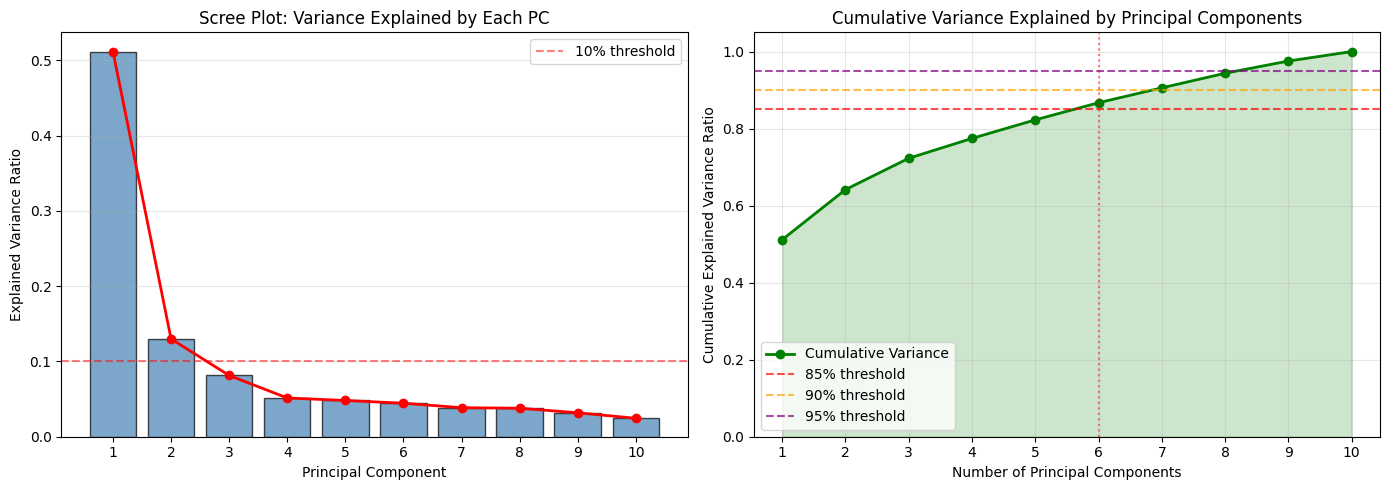

Figure saved: pca_variance_analysis.png


In [13]:
# Create variance plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Scree plot
axes[0].bar(range(1, len(explained_variance_ratio)+1), explained_variance_ratio,
           alpha=0.7, color='steelblue', edgecolor='black')
axes[0].plot(range(1, len(explained_variance_ratio)+1), explained_variance_ratio,
            'ro-', linewidth=2, markersize=6)
axes[0].axhline(0.1, color='red', linestyle='--', alpha=0.5, label='10% threshold')
axes[0].set_xlabel('Principal Component')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot: Variance Explained by Each PC')
axes[0].grid(True, alpha=0.3, axis='y')
axes[0].legend()
axes[0].set_xticks(range(1, len(explained_variance_ratio)+1))

# Plot 2: Cumulative variance
axes[1].plot(range(1, len(cumulative_variance_ratio)+1), cumulative_variance_ratio,
            'go-', linewidth=2, markersize=6, label='Cumulative Variance')
axes[1].axhline(0.85, color='red', linestyle='--', alpha=0.7, label='85% threshold')
axes[1].axhline(0.90, color='orange', linestyle='--', alpha=0.7, label='90% threshold')
axes[1].axhline(0.95, color='purple', linestyle='--', alpha=0.7, label='95% threshold')
axes[1].axvline(n_components_85, color='red', linestyle=':', alpha=0.5)
axes[1].fill_between(range(1, len(cumulative_variance_ratio)+1), 0, cumulative_variance_ratio,
                    alpha=0.2, color='green')
axes[1].set_xlabel('Number of Principal Components')
axes[1].set_ylabel('Cumulative Explained Variance Ratio')
axes[1].set_title('Cumulative Variance Explained by Principal Components')
axes[1].grid(True, alpha=0.3)
axes[1].legend()
axes[1].set_xticks(range(1, len(cumulative_variance_ratio)+1))
axes[1].set_ylim([0, 1.05])

plt.tight_layout()
plt.savefig('pca_variance_analysis.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"Figure saved: pca_variance_analysis.png")

## 3.4: Principal Component Loadings


Principal Component Loadings (First 6 Components):
          PC1     PC2     PC3     PC4     PC5     PC6
AAPL   0.3439 -0.1612 -0.0631  0.1688  0.6926  0.0073
MSFT   0.3613 -0.1993 -0.1093  0.0698  0.2376 -0.1423
GOOGL  0.3583 -0.2707 -0.2046  0.1017 -0.2190  0.0007
AMZN   0.3363 -0.3076 -0.2237  0.0029 -0.3895  0.1038
JPM    0.2463  0.5301 -0.3001  0.0310  0.0707  0.7371
XOM    0.2073  0.5746 -0.4438 -0.1162 -0.0668 -0.6308
JNJ    0.2764  0.2902  0.5169  0.6862 -0.0694 -0.1365
WMT    0.3134  0.1027  0.4367 -0.6514  0.2538 -0.0295
V      0.3469 -0.2144 -0.0835 -0.0593 -0.1161 -0.0463
PG     0.3333  0.1206  0.3746 -0.2075 -0.4148  0.0778


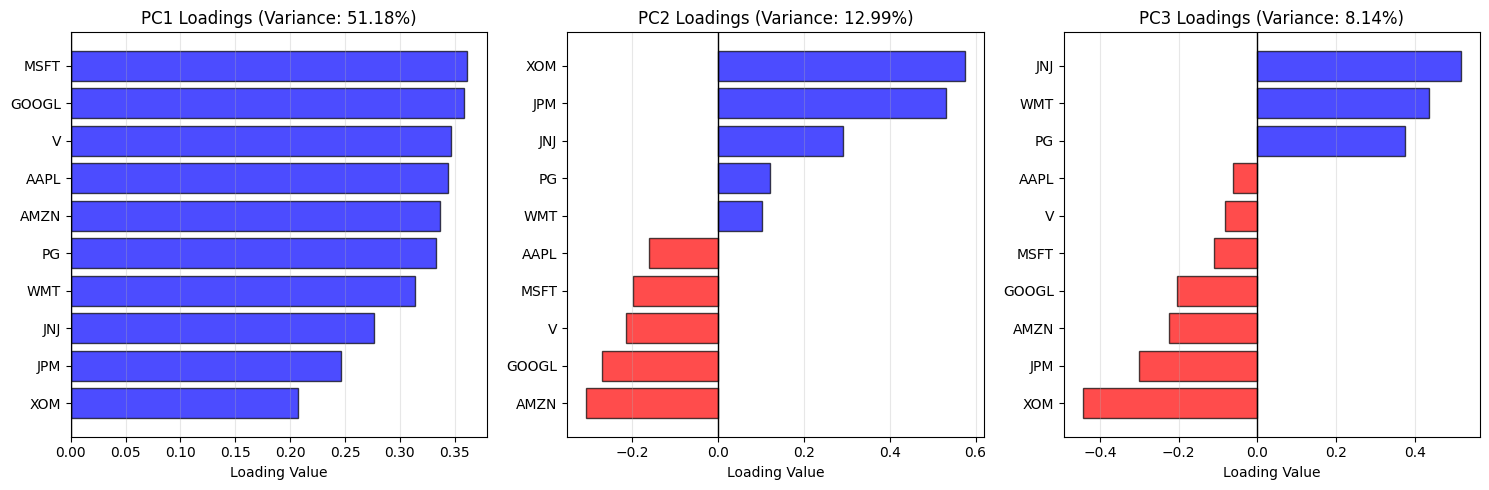


Figure saved: pca_loadings.png


In [14]:
# Extract loadings (components)
loadings = pca.components_[:n_components_85].T  # Transpose for readability

loadings_df = pd.DataFrame(
    loadings,
    columns=[f'PC{i+1}' for i in range(n_components_85)],
    index=returns.columns
)

print(f"\nPrincipal Component Loadings (First {n_components_85} Components):")
print(loadings_df.round(4))

# Visualization of loadings
fig, axes = plt.subplots(1, min(3, n_components_85), figsize=(15, 5))

if n_components_85 == 1:
    axes = [axes]
elif n_components_85 == 2:
    axes = list(axes)

for i in range(min(3, n_components_85)):
    loadings_pc = loadings_df[f'PC{i+1}'].sort_values()
    colors_bar = ['red' if x < 0 else 'blue' for x in loadings_pc.values]
    axes[i].barh(range(len(loadings_pc)), loadings_pc.values, color=colors_bar, alpha=0.7, edgecolor='black')
    axes[i].set_yticks(range(len(loadings_pc)))
    axes[i].set_yticklabels(loadings_pc.index)
    axes[i].set_xlabel('Loading Value')
    axes[i].set_title(f'PC{i+1} Loadings (Variance: {explained_variance_ratio[i]*100:.2f}%)')
    axes[i].grid(True, alpha=0.3, axis='x')
    axes[i].axvline(0, color='black', linewidth=1)

plt.tight_layout()
plt.savefig('pca_loadings.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"\nFigure saved: pca_loadings.png")

### Interpretation of PCA Results\n\nThe PCA reveals the latent factors driving the returns of this 10-stock portfolio:\n\n- **PC1 (51.18% of Variance):** This component has positive loadings for all 10 stocks, indicating it represents the overall market movement. A rise in PC1 corresponds to a general rise in the market. Its high explained variance (51.18%) confirms that the primary driver of returns is the market itself.\n\n- **PC2 (12.99% of Variance):** This component shows a clear divergence. It has strong positive loadings on 'JPM' and 'XOM' (Financials/Energy) and strong negative loadings on 'AMZN', 'GOOGL', 'AAPL', 'MSFT', and 'V' (Tech/Growth). This component can be interpreted as a **sector rotation factor**, capturing the opposition between value/cyclical stocks and growth/technology stocks.\n\n- **PC3 (8.14% of Variance):** This component has strong positive loadings on 'JNJ' and 'WMT' and negative loadings on the others. This may represent a 'defensive' vs. 'cyclical' factor.

## 3.5: PCA-Reduced Data Visualization

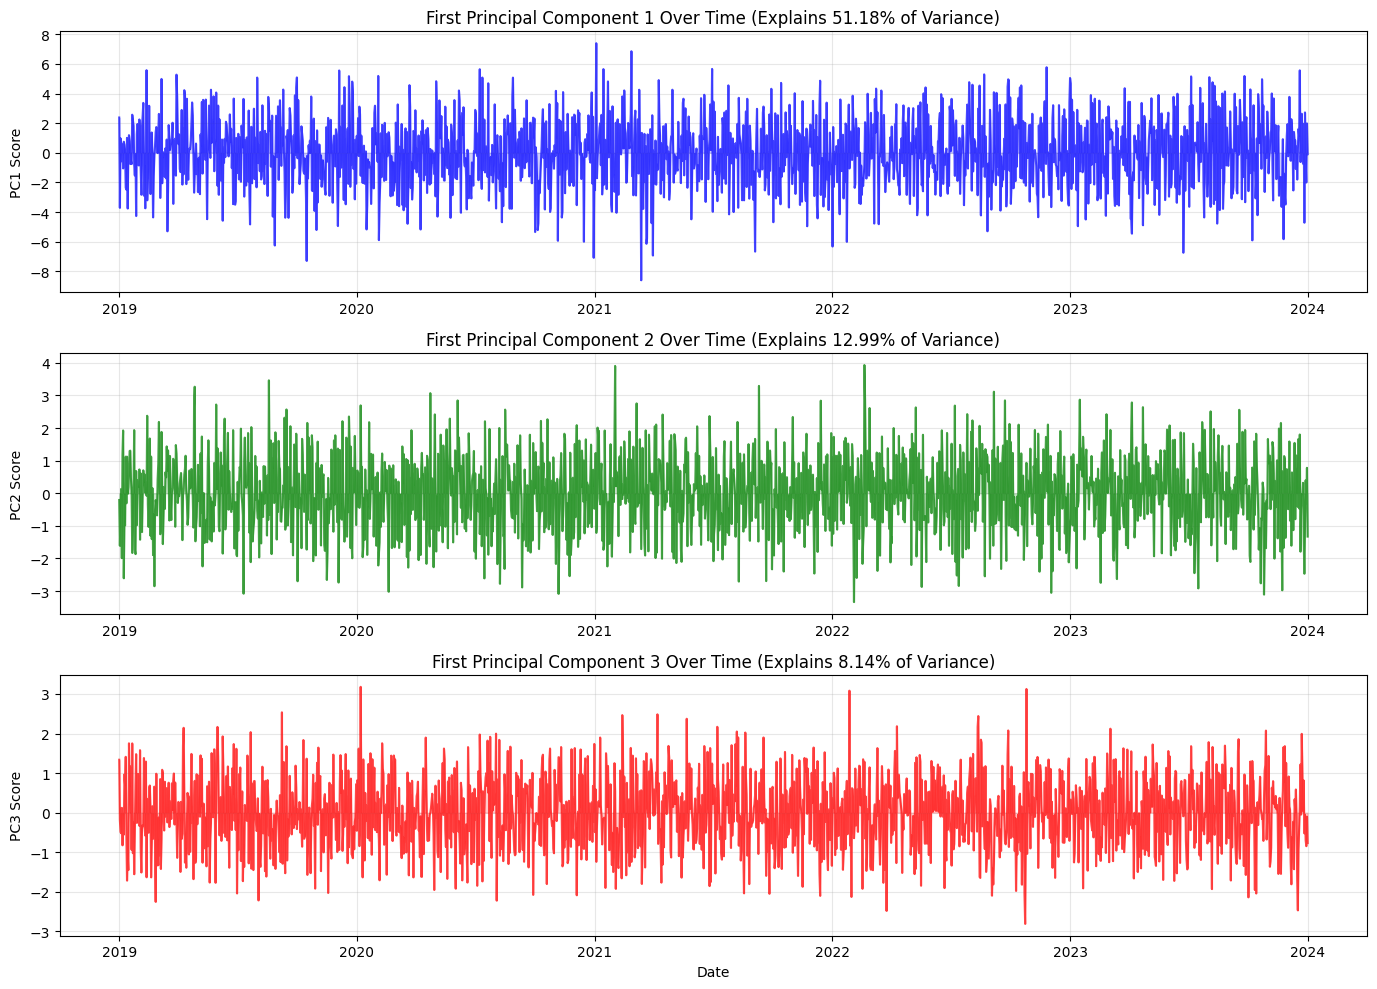

Figure saved: pca_timeseries.png


In [15]:
# Apply PCA with reduced dimensions
pca_reduced = PCA(n_components=3)
pca_data_3d = pca_reduced.fit_transform(returns_scaled)

# Time series plot of first three PCs
fig, axes = plt.subplots(3, 1, figsize=(14, 10))

time_index = returns.index

for i in range(3):
    axes[i].plot(time_index, pca_data_3d[:, i], linewidth=1.5, alpha=0.7, color=['blue', 'green', 'red'][i])
    axes[i].fill_between(time_index, pca_data_3d[:, i], alpha=0.2, color=['blue', 'green', 'red'][i])
    axes[i].set_ylabel(f'PC{i+1} Score')
    axes[i].set_title(f'First Principal Component {i+1} Over Time (Explains {pca_reduced.explained_variance_ratio_[i]*100:.2f}% of Variance)')
    axes[i].grid(True, alpha=0.3)

axes[2].set_xlabel('Date')

plt.tight_layout()
plt.savefig('pca_timeseries.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"Figure saved: pca_timeseries.png")

## 3.6: PCA Reconstruction Error

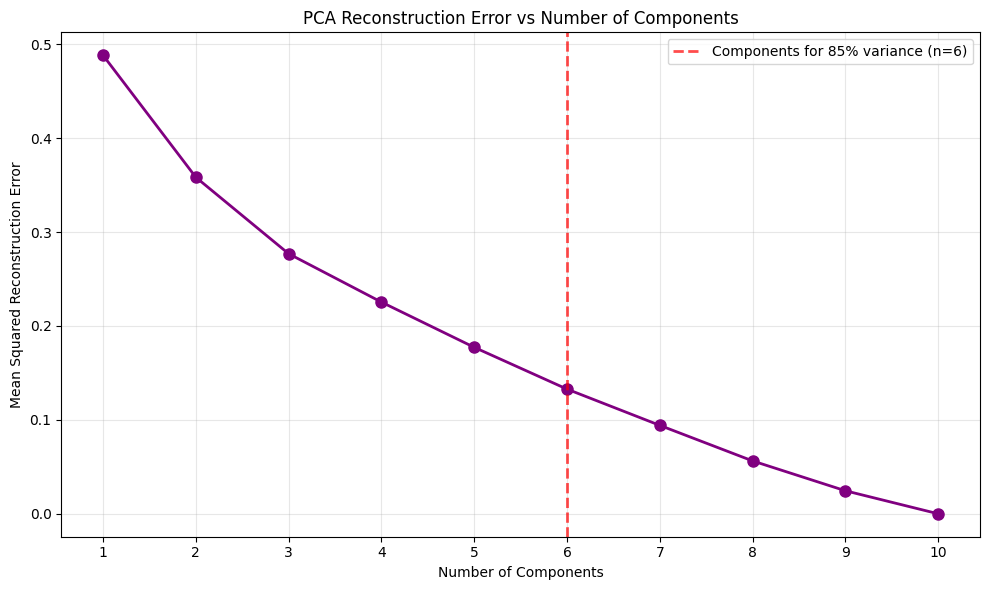

Figure saved: pca_reconstruction_error.png


In [16]:
# Calculate reconstruction error for different numbers of components
reconstruction_errors = []
n_components_range = range(1, len(returns.columns) + 1)

for n_comp in n_components_range:
    pca_temp = PCA(n_components=n_comp)
    pca_transformed_temp = pca_temp.fit_transform(returns_scaled)
    pca_reconstructed = pca_temp.inverse_transform(pca_transformed_temp)
    error = np.mean((returns_scaled - pca_reconstructed) ** 2)
    reconstruction_errors.append(error)

# Plot reconstruction error
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(n_components_range, reconstruction_errors, 'o-', linewidth=2, markersize=8, color='purple')
ax.axvline(n_components_85, color='red', linestyle='--', linewidth=2, alpha=0.7,
          label=f'Components for 85% variance (n={n_components_85})')
ax.set_xlabel('Number of Components')
ax.set_ylabel('Mean Squared Reconstruction Error')
ax.set_title('PCA Reconstruction Error vs Number of Components')
ax.grid(True, alpha=0.3)
ax.legend()
ax.set_xticks(n_components_range)

plt.tight_layout()
plt.savefig('pca_reconstruction_error.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"Figure saved: pca_reconstruction_error.png")

---

## Summary Statistics

This concludes the computational demonstrations of the three machine learning techniques.

In [17]:
# Summary of all three methods
print("="*80)
print("COMPREHENSIVE SUMMARY OF ALL THREE MACHINE LEARNING TECHNIQUES")
print("="*80)

print("\n1. LASSO REGRESSION")
print("-" * 40)
print(f"   Objective: Predict next day AAPL return from lagged returns")
print(f"   Optimal Lambda: {best_lambda_lasso:.6f}")
print(f"   Features Selected: {np.sum(lasso_cv.coef_ != 0)} out of {len(lasso_cv.coef_)}")
print(f"   Training MSE: {mse_train_lasso:.8f}")
print(f"   Test MSE: {mse_test_lasso:.8f}")

print("\n2. K-MEANS CLUSTERING")
print("-" * 40)
print(f"   Objective: Segment stocks by risk-return characteristics")
print(f"   Optimal K: {optimal_clusters}")
print(f"   Final Inertia: {kmeans_final.inertia_:.4f}")
print(f"   Silhouette Score: {silhouette_score(features_kmeans_scaled, clusters):.4f}")
for i in range(optimal_clusters):
    print(f"   Cluster {i}: {features_kmeans[features_kmeans['Cluster'] == i].index.tolist()}")

print("\n3. PRINCIPAL COMPONENT ANALYSIS")
print("-" * 40)
print(f"   Objective: Dimensionality reduction of stock returns")
print(f"   Total Components: {len(explained_variance_ratio)}")
print(f"   PC1 Variance Explained: {explained_variance_ratio[0]*100:.2f}%")
print(f"   PC1+PC2 Variance Explained: {cumulative_variance_ratio[1]*100:.2f}%")
print(f"   PC1+PC2+PC3 Variance Explained: {cumulative_variance_ratio[2]*100:.2f}%")
print(f"   Components for 85% variance: {n_components_85}")

print("\n" + "="*80)
print("All computations completed successfully!")
print("="*80)

COMPREHENSIVE SUMMARY OF ALL THREE MACHINE LEARNING TECHNIQUES

1. LASSO REGRESSION
----------------------------------------
   Objective: Predict next day AAPL return from lagged returns
   Optimal Lambda: 0.001039
   Features Selected: 0 out of 50
   Training MSE: 0.00033931
   Test MSE: 0.00032842

2. K-MEANS CLUSTERING
----------------------------------------
   Objective: Segment stocks by risk-return characteristics
   Optimal K: 3
   Final Inertia: 13.8286
   Silhouette Score: 0.3629
   Cluster 0: ['MSFT', 'JNJ', 'PG']
   Cluster 1: ['AAPL', 'GOOGL', 'AMZN', 'V']
   Cluster 2: ['JPM', 'XOM', 'WMT']

3. PRINCIPAL COMPONENT ANALYSIS
----------------------------------------
   Objective: Dimensionality reduction of stock returns
   Total Components: 10
   PC1 Variance Explained: 51.18%
   PC1+PC2 Variance Explained: 64.17%
   PC1+PC2+PC3 Variance Explained: 72.31%
   Components for 85% variance: 6

All computations completed successfully!
